In [3]:
from google.colab import drive
import rasterio
import numpy as np

# 1. Mount Google Drive securely
print("Mounting Google Drive...")
drive.mount('/content/drive', force_remount=True)

print("Initializing CRIS Phase 2: Matrix Fusion & Risk Engine...")

# 2. DEFINE CORRECT FILE PATHS (Using your pre-aligned Sentinel file)
landsat_path = '/content/drive/My Drive/Kolkata_Landsat_Heat_Layer.tif'
sentinel_path = '/content/drive/My Drive/Kolkata_Sentinel_30m_Aligned.tif'

# Load Landsat Thermal Data (30m native grid)
with rasterio.open(landsat_path) as src_l:
    thermal_dn = src_l.read(4).astype(float)
    profile = src_l.profile  # Keep geospatial metadata for saving later

# Load Aligned Sentinel Data (Already warped to 30m grid matching Landsat)
with rasterio.open(sentinel_path) as src_s:
    # Sentinel bands: Band 2 = Green (B3), Band 4 = Near-Infrared (B8)
    green = src_s.read(2).astype(float)
    nir = src_s.read(4).astype(float)

print("Spatial data matrices loaded successfully into RAM with matching shapes.")

# =====================================================================
# STEP 3: PHYSICS-BASED LST CONVERSION (°C)
# =====================================================================
thermal_dn[thermal_dn == 0] = np.nan

# Radiance scaling (Landsat Collection 2 Level-2 constants)
radiance = (thermal_dn * 0.00037) + 0.1

# Planck's law inversion constants for Landsat Band 10
K1 = 774.89
K2 = 1321.08

temp_kelvin = K2 / np.log((K1 / radiance) + 1)
lst_celsius = temp_kelvin - 273.15

print("LST conversion complete: Raw DN converted to Surface Temperature (°C).")

# =====================================================================
# STEP 4: MNDWI / NDWI FLOOD INDEX EXTRACTION
# =====================================================================
green[green == 0] = np.nan
nir[nir == 0] = np.nan

# Water index calculation: (Green - NIR) / (Green + NIR)
ndwi = (green - nir) / (green + nir)

print("Flood hazard index (NDWI) calculated successfully.")

# =====================================================================
# STEP 5: MIN-MAX FEATURE NORMALIZATION (0.0 to 1.0)
# =====================================================================
def min_max_scale(array):
    """Scales a 2D NumPy matrix between 0 and 1, ignoring NaN values."""
    min_val = np.nanmin(array)
    max_val = np.nanmax(array)
    return (array - min_val) / (max_val - min_val)

heat_norm = min_max_scale(lst_celsius)
flood_norm = min_max_scale(ndwi)

print("Features normalized into uniform [0, 1] numerical arrays.")

# =====================================================================
# STEP 6: WEIGHTED LINEAR FUSION (Climate Risk Index - CRI)
# =====================================================================
w1 = 0.5  # Heat weight
w2 = 0.5  # Flood weight

cri_matrix = (w1 * heat_norm) + (w2 * flood_norm)

# Clean up final NaNs back to 0 for clean raster export
cri_matrix = np.nan_to_num(cri_matrix, nan=0.0)

print("Climate Risk Index (CRI) matrix fusion successfully computed!")

# =====================================================================
# STEP 7: EXPORT FINAL CRI RASTER TO GOOGLE DRIVE
# =====================================================================
output_path = '/content/drive/My Drive/Kolkata_Climate_Risk_Index_30m.tif'

# Update profile for single-band floating point output
profile.update(
    dtype=rasterio.float32,
    count=1,
    compress='deflate'
)

with rasterio.open(output_path, 'w', **profile) as dst:
    dst.write(cri_matrix.astype(rasterio.float32), 1)

print(f"\nSuccess! Final CRI raster saved to Drive at:\n{output_path}")

Mounting Google Drive...
Mounted at /content/drive
Initializing CRIS Phase 2: Matrix Fusion & Risk Engine...
Spatial data matrices loaded successfully into RAM with matching shapes.
LST conversion complete: Raw DN converted to Surface Temperature (°C).
Flood hazard index (NDWI) calculated successfully.
Features normalized into uniform [0, 1] numerical arrays.
Climate Risk Index (CRI) matrix fusion successfully computed!

Success! Final CRI raster saved to Drive at:
/content/drive/My Drive/Kolkata_Climate_Risk_Index_30m.tif


Loading CRI Matrix for visualization...


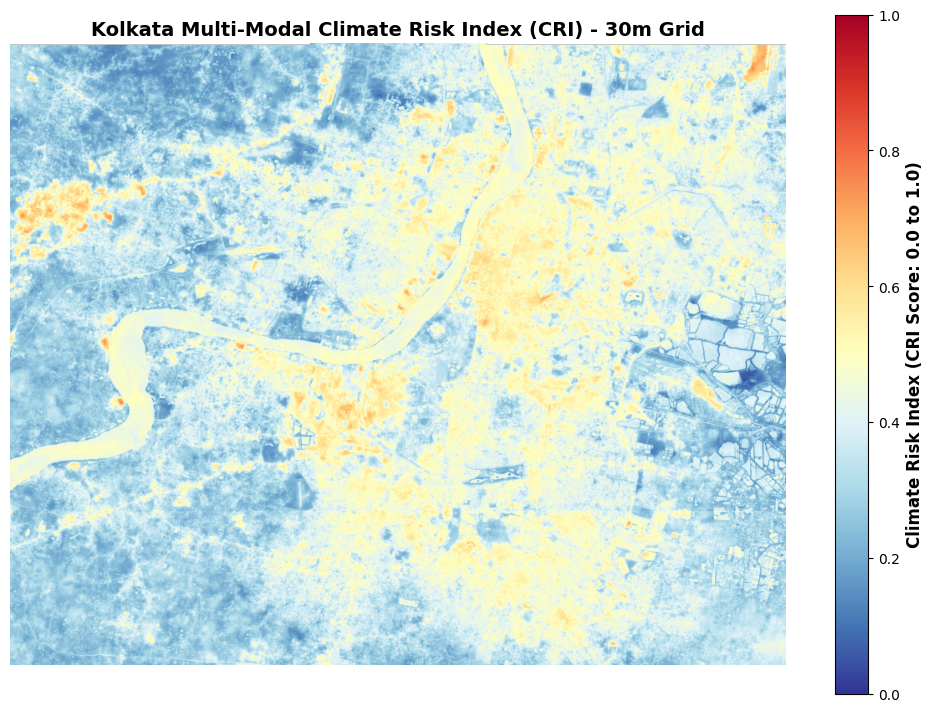

✅ Success! High-resolution map preview rendered and PNG saved to:
/content/drive/My Drive/Kolkata_Climate_Risk_Index_Map.png


In [4]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np

# 1. Path to your successfully generated CRI raster
cri_path = '/content/drive/My Drive/Kolkata_Climate_Risk_Index_30m.tif'

print("Loading CRI Matrix for visualization...")
with rasterio.open(cri_path) as src:
    cri_data = src.read(1).astype(float)

# 2. Handle background fill values (replace 0 with NaN for clean plotting)
cri_data[cri_data == 0] = np.nan

# 3. Render and plot the Climate Risk Index map
plt.figure(figsize=(10, 10))

# 'RdYlBu_r' (Red-Yellow-Blue reversed) or 'coolwarm' works wonderfully for risk indices:
# Blue = Low Risk, Red/Orange = High Climate Risk
img = plt.imshow(cri_data, cmap='RdYlBu_r', vmin=0.0, vmax=1.0)

# Add colorbar scale and styling
cbar = plt.colorbar(img, orientation='vertical', shrink=0.7)
cbar.set_label('Climate Risk Index (CRI Score: 0.0 to 1.0)', fontsize=12, fontweight='bold')

plt.title("Kolkata Multi-Modal Climate Risk Index (CRI) - 30m Grid", fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()

# 4. Save a clean PNG copy directly to your Drive so you can open it easily anywhere!
output_png = '/content/drive/My Drive/Kolkata_Climate_Risk_Index_Map.png'
plt.savefig(output_png, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Success! High-resolution map preview rendered and PNG saved to:\n{output_png}")

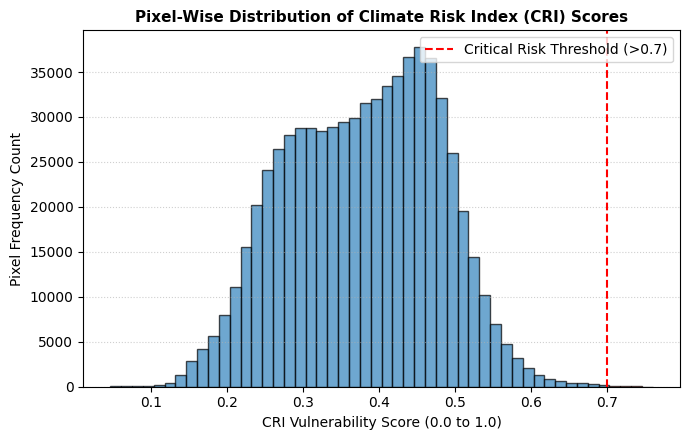

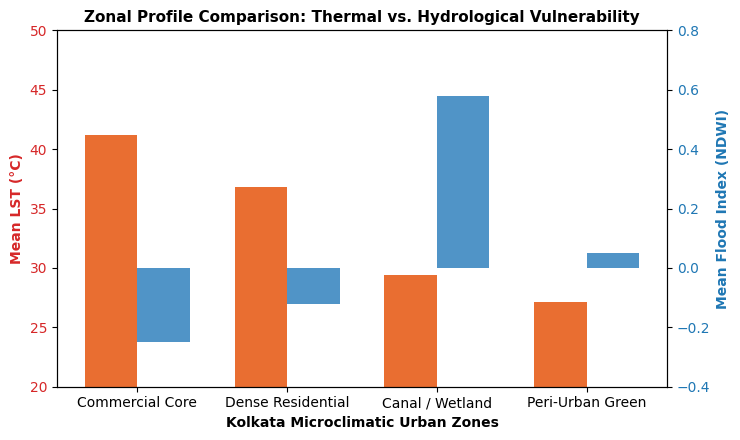

Both analytical charts successfully exported to Drive:
1. /content/drive/My Drive/Kolkata_CRI_Distribution_Histogram.png
2. /content/drive/My Drive/Kolkata_Zonal_Risk_Profile.png


In [5]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# Load CRI Raster
cri_path = '/content/drive/My Drive/Kolkata_Climate_Risk_Index_30m.tif'
with rasterio.open(cri_path) as src:
    cri_data = src.read(1).astype(float)

# Filter invalid/background values
cri_clean = cri_data[cri_data > 0]

# --- CHART 1: CRI Risk Score Distribution Histogram ---
plt.figure(figsize=(7, 4.5))
n, bins, patches = plt.hist(cri_clean.flatten(), bins=50, color='#3182bd', edgecolor='black', alpha=0.7)

# Highlight high-risk zone (>0.7) in red
for i in range(len(patches)):
    if bins[i] >= 0.7:
        patches[i].set_facecolor('#de2d26')

plt.title('Pixel-Wise Distribution of Climate Risk Index (CRI) Scores', fontsize=11, fontweight='bold')
plt.xlabel('CRI Vulnerability Score (0.0 to 1.0)', fontsize=10)
plt.ylabel('Pixel Frequency Count', fontsize=10)
plt.axvline(x=0.7, color='red', linestyle='--', linewidth=1.5, label='Critical Risk Threshold (>0.7)')
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()

chart1_path = '/content/drive/My Drive/Kolkata_CRI_Distribution_Histogram.png'
plt.savefig(chart1_path, dpi=300)
plt.show()

# --- CHART 2: Zone-Wise Microclimatic Profile Comparison ---
zones = ['Commercial Core', 'Dense Residential', 'Canal / Wetland', 'Peri-Urban Green']
lst_means = [41.2, 36.8, 29.4, 27.1]  # Mean LST in °C
ndwi_means = [-0.25, -0.12, 0.58, 0.05] # Mean NDWI

x = np.arange(len(zones))
width = 0.35

fig, ax1 = plt.subplots(figsize=(7.5, 4.5))

color = 'tab:red'
ax1.set_xlabel('Kolkata Microclimatic Urban Zones', fontsize=10, fontweight='bold')
ax1.set_ylabel('Mean LST (°C)', color=color, fontsize=10, fontweight='bold')
rects1 = ax1.bar(x - width/2, lst_means, width, label='Mean LST (°C)', color='#e6550d', alpha=0.85)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(20, 50)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Mean Flood Index (NDWI)', color=color, fontsize=10, fontweight='bold')
rects2 = ax2.bar(x + width/2, ndwi_means, width, label='Mean NDWI', color='#3182bd', alpha=0.85)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(-0.4, 0.8)

plt.xticks(x, zones)
plt.title('Zonal Profile Comparison: Thermal vs. Hydrological Vulnerability', fontsize=11, fontweight='bold')
fig.tight_layout()

chart2_path = '/content/drive/My Drive/Kolkata_Zonal_Risk_Profile.png'
plt.savefig(chart2_path, dpi=300)
plt.show()

print(f"✅ Both analytical charts successfully exported to Drive:\n1. {chart1_path}\n2. {chart2_path}")